# SARIMA / AutoSARIMA

L'anàlisi exploratòria (EDA) va confirmar dos trets centrals de les nostres sèries: tendència creixent i estacionalitat anual forta (pics a tardor, vall a agost). El test ADF també va mostrar que la sèrie no és estacionària en nivell però sí en primera diferència. Tot plegat fa que la família de models SARIMA sigui una elecció natural i ben fonamentada per a aquest problema.

Un model SARIMA(p,d,q)(P,D,Q)₁₂ gestiona explícitament la no-estacionarietat via diferenciació (d=1 confirmat per l'ADF, D=1 per eliminar l'estacionalitat), l'autocorrelació a curt termini via els termes AR/MA (p, q), i l'estacionalitat periòdica de 12 mesos via els termes estacionals (P, Q).

En lloc d'escollir manualment els ordres — un procés costós i subjectiu per a 7 sèries independents — fem servir `auto_arima` de pmdarima, que cerca l'ordre òptim minimitzant l'AIC. Obtenim així un model ben calibrat per a cada tecnologia sense intervenció manual, i podem veure quins ordres tria el criteri per a cada sèrie (un resultat interessant per si sol).

S'ha provat també una variant SARIMAX amb dummies de COVID i MOVES III com a variables exògenes. Durant el període de test (2025), però, el COVID és zero i MOVES III és actiu tots els mesos, de manera que les prediccions resulten pràcticament idèntiques. Reportem només AutoSARIMA per evitar la redundància.

> Prerequisit: executar `data_preparation.ipynb` primer.

In [1]:
import sys
sys.path.insert(0, '../../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

from features import TECNOLOGIES_MODELITZABLES
from evaluation import compute_metrics
from models import SARIMAForecaster
from plotting import format_ts_ax

DATA_DIR    = Path('../../data/processed')
RESULTS_DIR = DATA_DIR / 'results'
FIGURES_DIR = Path('../../figures')

plt.rcParams.update({'figure.dpi': 120})
TECNOLOGIES = TECNOLOGIES_MODELITZABLES + ['Total']

In [2]:
pivot_train = pd.read_csv(DATA_DIR / 'pivot_train.csv', index_col='date', parse_dates=True)
pivot_test  = pd.read_csv(DATA_DIR / 'pivot_test.csv',  index_col='date', parse_dates=True)
train_set   = pd.read_csv(DATA_DIR / 'train_set.csv',   parse_dates=['date'])
test_set    = pd.read_csv(DATA_DIR / 'test_set.csv',    parse_dates=['date'])

# Dummies exògenes: una fila per mes (independentment de tecnologia)
exog_train = train_set[train_set['Tecnologia'] == 'Total'][['date', 'covid_dummy', 'moves3_dummy']].set_index('date')
exog_test  = test_set[test_set['Tecnologia'] == 'Total'][['date', 'covid_dummy', 'moves3_dummy']].set_index('date')
print(f'Train: {len(pivot_train)} mesos | Exog train shape: {exog_train.shape}')
print(f'Test:  {len(pivot_test)} mesos | Exog test shape:  {exog_test.shape}')

Train: 96 mesos | Exog train shape: (96, 2)
Test:  12 mesos | Exog test shape:  (12, 2)


## 1. AutoSARIMA — selecció d'ordres i predicció


In [3]:
H = len(pivot_test)

sarima_forecasts = {}
sarima_orders    = {}
forecast_records = []
metrics_records  = []

print('Ajustant AutoSARIMA per tecnologia...')
for tech in TECNOLOGIES:
    y_train = pivot_train[tech].dropna()
    y_test  = pivot_test[tech].values

    model = SARIMAForecaster(name='AutoSARIMA')
    model.fit(y_train)
    y_pred = np.maximum(model.predict(H), 0)
    sarima_forecasts[tech] = y_pred

    order = model._model.order
    seas  = model._model.seasonal_order
    sarima_orders[tech] = {'order': order, 'seasonal_order': seas}
    print(f'  {tech:35s}: SARIMA{order}×{seas}')

    m = compute_metrics(y_test, y_pred, y_train.values)
    m.update({'Tecnologia': tech, 'Model': 'AutoSARIMA'})
    metrics_records.append(m)

    for i, date in enumerate(pivot_test.index):
        forecast_records.append({'date': date, 'Tecnologia': tech,
                                 'Model': 'AutoSARIMA',
                                 'predicted': y_pred[i], 'actual': y_test[i]})

Ajustant AutoSARIMA per tecnologia...


  Elèctric                           : SARIMA(3, 1, 1)×(2, 1, 0, 12)


  Gasolina Mild Hybrid               : SARIMA(1, 1, 3)×(0, 1, 1, 12)


  Gasolina/Elèctric                  : SARIMA(0, 1, 1)×(0, 1, 1, 12)


  Gasolina/Elèctric Endollable       : SARIMA(2, 1, 1)×(0, 1, 1, 12)


  Diesel Mild Hybrid                 : SARIMA(0, 1, 2)×(2, 1, 0, 12)


  Diesel/Elèctric Endollable         : SARIMA(0, 1, 1)×(2, 1, 0, 12)


  Total                              : SARIMA(0, 1, 1)×(0, 1, 1, 12)


## 2. Diagnòstic de residus (sèrie Total)

In [4]:
from statsmodels.stats.diagnostic import acorr_ljungbox

y_total = pivot_train['Total'].dropna()
model_diag = SARIMAForecaster(name='SARIMA_diag')
model_diag.fit(y_total)

residuals = model_diag._model.resid()
lb_result = acorr_ljungbox(residuals, lags=[6, 12, 24], return_df=True)
print('Test de Ljung-Box sobre residus (H0: no autocorrelació):')
print(lb_result)
if (lb_result['lb_pvalue'] > 0.05).all():
    print('\n✓ Residus sense autocorrelació significativa (p > 0.05)')
else:
    print('\n⚠ Autocorrelació residual detectada — considera augmentar l\'ordre')

Test de Ljung-Box sobre residus (H0: no autocorrelació):
      lb_stat  lb_pvalue
6   16.828062   0.009936
12  19.833289   0.070306
24  28.843129   0.226091

⚠ Autocorrelació residual detectada — considera augmentar l'ordre


## 3. Mètriques i visualització

In [5]:
df_metrics   = pd.DataFrame(metrics_records)
df_forecasts = pd.DataFrame(forecast_records)

print('Mètriques AutoSARIMA (totes les tecnologies):')
display(df_metrics.set_index('Tecnologia')[['RMSE', 'MAE', 'MAPE', 'MASE']].round(2))

print(f'\nMitjana global: MASE={df_metrics["MASE"].mean():.2f}')

orders_df = pd.DataFrame([
    {'Tecnologia': t, 'order': v['order'], 'seasonal_order': v['seasonal_order']}
    for t, v in sarima_orders.items()
])
print('\nOrdres seleccionats per AutoAIC:')
orders_df

Mètriques AutoSARIMA (totes les tecnologies):


,RMSE,MAE,MAPE,MASE
Tecnologia,,,,
Elèctric,507.55,453.76,25.51,1.37
Gasolina Mild Hybrid,198.67,146.31,7.69,0.56
Gasolina/Elèctric,212.30,170.51,6.98,0.60
Gasolina/Elèctric Endollable,650.91,580.04,41.08,4.50
Diesel Mild Hybrid,42.82,34.33,12.11,0.56
Diesel/Elèctric Endollable,16.00,12.45,28.90,1.50
Total,1348.53,1176.45,13.80,1.35



Mitjana global: MASE=1.49

Ordres seleccionats per AutoAIC:


,Tecnologia,order,seasonal_order
0,Elèctric,"(3, 1, 1)","(2, 1, 0, 12)"
1,Gasolina Mild Hybrid,"(1, 1, 3)","(0, 1, 1, 12)"
2,Gasolina/Elèctric,"(0, 1, 1)","(0, 1, 1, 12)"
3,Gasolina/Elèctric Endollable,"(2, 1, 1)","(0, 1, 1, 12)"
4,Diesel Mild Hybrid,"(0, 1, 2)","(2, 1, 0, 12)"
5,Diesel/Elèctric Endollable,"(0, 1, 1)","(2, 1, 0, 12)"
6,Total,"(0, 1, 1)","(0, 1, 1, 12)"


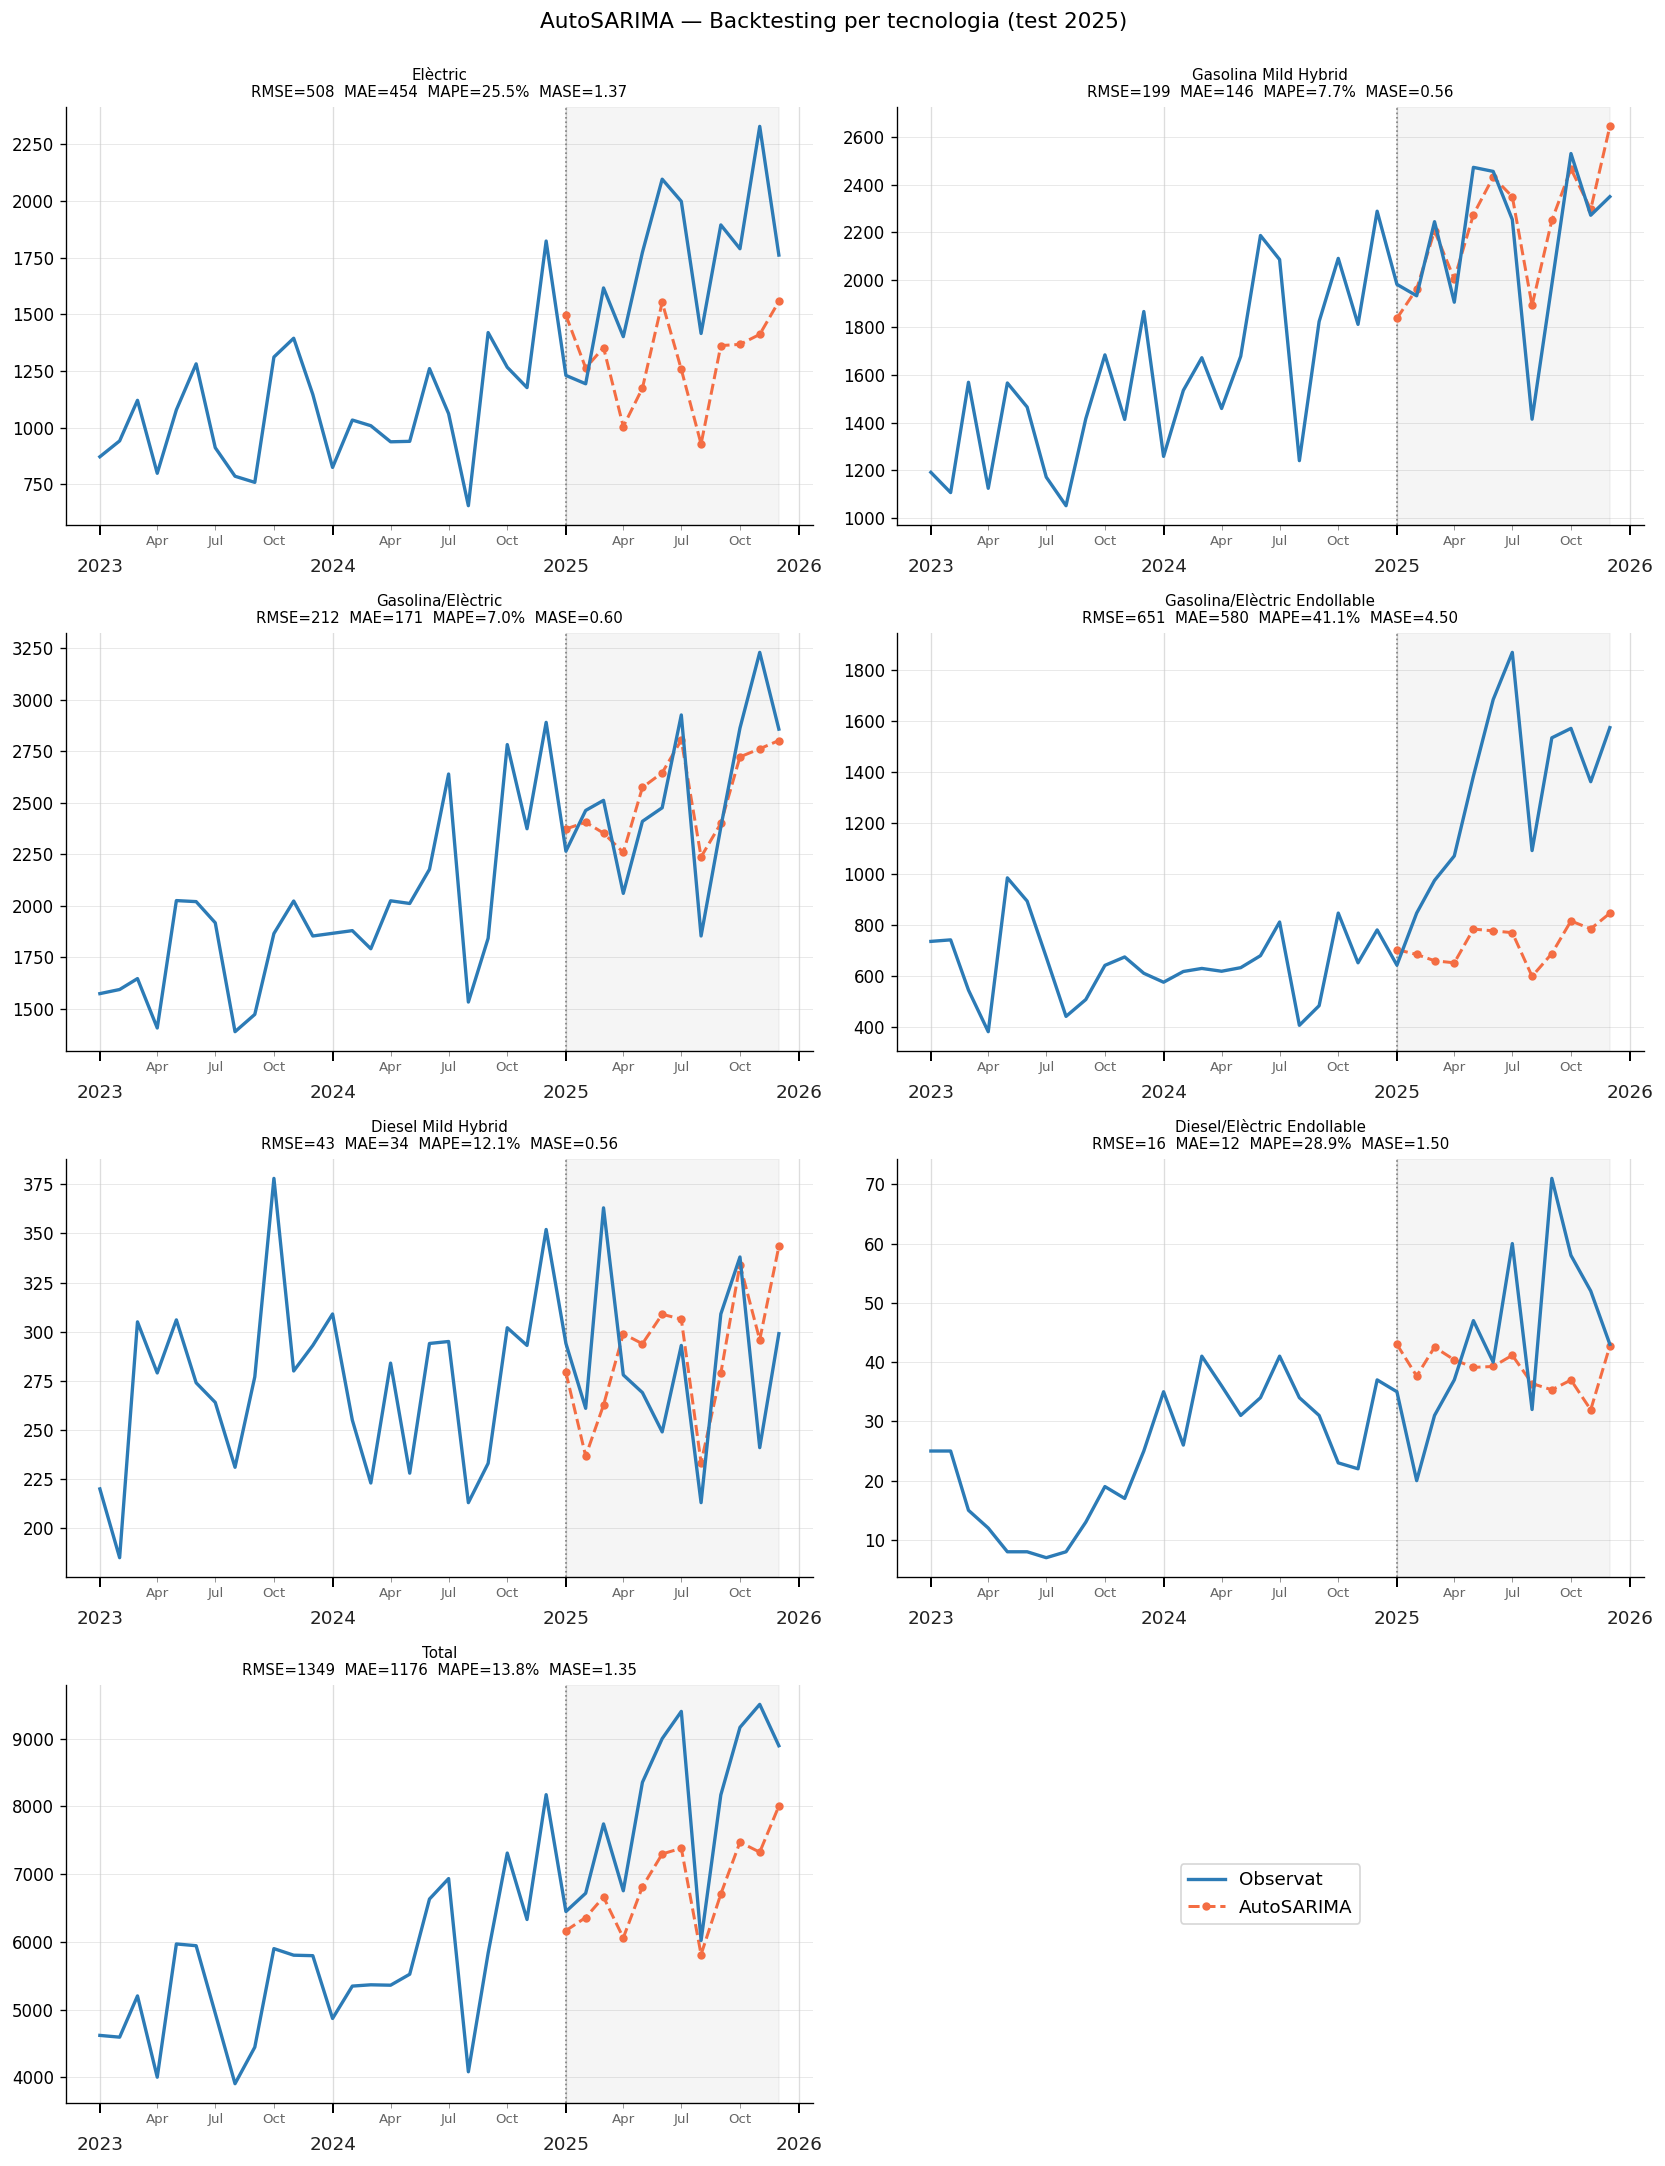

In [6]:
from plotting import plot_backtest_per_tech

plot_backtest_per_tech(
    pivot_train, pivot_test, df_forecasts, df_metrics,
    tecnologies=TECNOLOGIES, model_name='AutoSARIMA',
    save_path=FIGURES_DIR / 'fig_sarima_backtest_per_tech.png',
    color_pred='#f46d43',
)
plt.show()

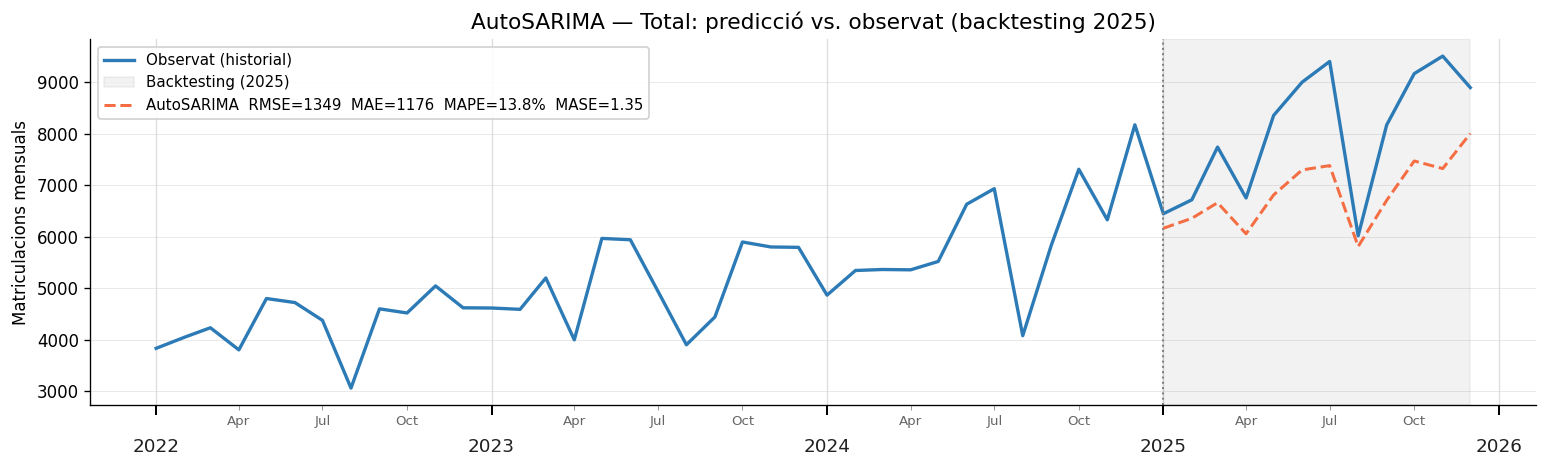

In [7]:
tech = 'Total'
fig, ax = plt.subplots(figsize=(13, 4))

y_train_plot = pivot_train[tech].iloc[-36:]
y_test_plot  = pivot_test[tech]
observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)
ax.plot(observed_dates, observed_vals, color='#2c7bb6', lw=2, label='Observat (historial)')

ax.axvspan(pivot_test.index[0], pivot_test.index[-1], alpha=0.10, color='gray', label='Backtesting (2025)')
ax.axvline(pivot_test.index[0], color='gray', ls=':', lw=1.2)

sub = df_forecasts[(df_forecasts['Tecnologia'] == tech) &
                   (df_forecasts['Model'] == 'AutoSARIMA')].sort_values('date')
m_total = df_metrics[df_metrics['Tecnologia'] == tech].iloc[0]
label = (f'AutoSARIMA  RMSE={m_total["RMSE"]:.0f}  MAE={m_total["MAE"]:.0f}  '
         f'MAPE={m_total["MAPE"]:.1f}%  MASE={m_total["MASE"]:.2f}')
ax.plot(sub['date'], sub['predicted'], color='#f46d43', lw=1.8, ls='--', label=label)

ax.set_title(f'AutoSARIMA — {tech}: predicció vs. observat (backtesting 2025)', fontsize=13)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=9, framealpha=0.9)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_10_sarima_total.png', bbox_inches='tight')
plt.show()

## 4. Walk-forward validation (rolling-origin)

Replicació del backtest amb 13 origins per sèrie (`initial=60`, `step=3`, `horizon=12`). A cada fold, `auto_arima` torna a seleccionar l'ordre òptim sobre la finestra expandida. Cost aproximat: ~30s per fold × 13 folds × 7 tecnologies ≈ 45 minuts.

In [8]:
from evaluation import walk_forward_cv_full

pivot_full = pd.concat([pivot_train, pivot_test]).sort_index()

def sarima_fn(train_series):
    m = SARIMAForecaster()
    m.fit(train_series)
    return np.maximum(m.predict(H), 0)

import time
wfv_metric_rows  = []
wfv_forecast_rows = []
print('Walk-forward AutoSARIMA (initial=60, step=3, horizon=12)...')
t0 = time.time()
for tech in TECNOLOGIES:
    t_start = time.time()
    series = pivot_full[tech].dropna()
    m_df, f_df = walk_forward_cv_full(series, sarima_fn, initial=60, step=3, horizon=H)
    m_df['Tecnologia'] = tech
    m_df['Model']      = 'AutoSARIMA'
    f_df['Tecnologia'] = tech
    f_df['Model']      = 'AutoSARIMA'
    wfv_metric_rows.append(m_df)
    wfv_forecast_rows.append(f_df)
    mase_mean = m_df['MASE'].mean() if 'MASE' in m_df.columns else float('nan')
    print(f'  {tech:35s}: {len(m_df)} folds, MASE_mean={mase_mean:.2f}, {time.time()-t_start:.0f}s')
print(f'Total: {(time.time()-t0)/60:.1f} min')

df_wfv_metrics   = pd.concat(wfv_metric_rows, ignore_index=True)
df_wfv_forecasts = pd.concat(wfv_forecast_rows, ignore_index=True)

wfv_agg = (df_wfv_metrics.dropna(subset=['MASE'])
           .groupby('Tecnologia')[['RMSE', 'MAE', 'MAPE', 'MASE']]
           .mean().round(2).reset_index())
print('\nMitjana WFV per tecnologia:')
display(wfv_agg.set_index('Tecnologia'))

Walk-forward AutoSARIMA (initial=60, step=3, horizon=12)...


  Elèctric                           : 13 folds, MASE_mean=1.06, 82s


  Gasolina Mild Hybrid               : 13 folds, MASE_mean=0.74, 132s


  Gasolina/Elèctric                  : 13 folds, MASE_mean=0.97, 200s


  Gasolina/Elèctric Endollable       : 13 folds, MASE_mean=1.82, 105s


  Diesel Mild Hybrid                 : 13 folds, MASE_mean=0.76, 71s


  Diesel/Elèctric Endollable         : 13 folds, MASE_mean=1.79, 143s


  Total                              : 13 folds, MASE_mean=0.82, 182s
Total: 15.3 min

Mitjana WFV per tecnologia:


,RMSE,MAE,MAPE,MASE
Tecnologia,,,,
Diesel Mild Hybrid,60.10,49.86,19.73,0.76
Diesel/Elèctric Endollable,15.41,12.27,83.88,1.79
Elèctric,450.34,385.70,36.73,1.06
Gasolina Mild Hybrid,216.42,178.24,11.87,0.74
Gasolina/Elèctric,311.86,246.37,12.63,0.97
Gasolina/Elèctric Endollable,266.01,224.45,28.43,1.82
Total,826.31,702.87,11.88,0.82


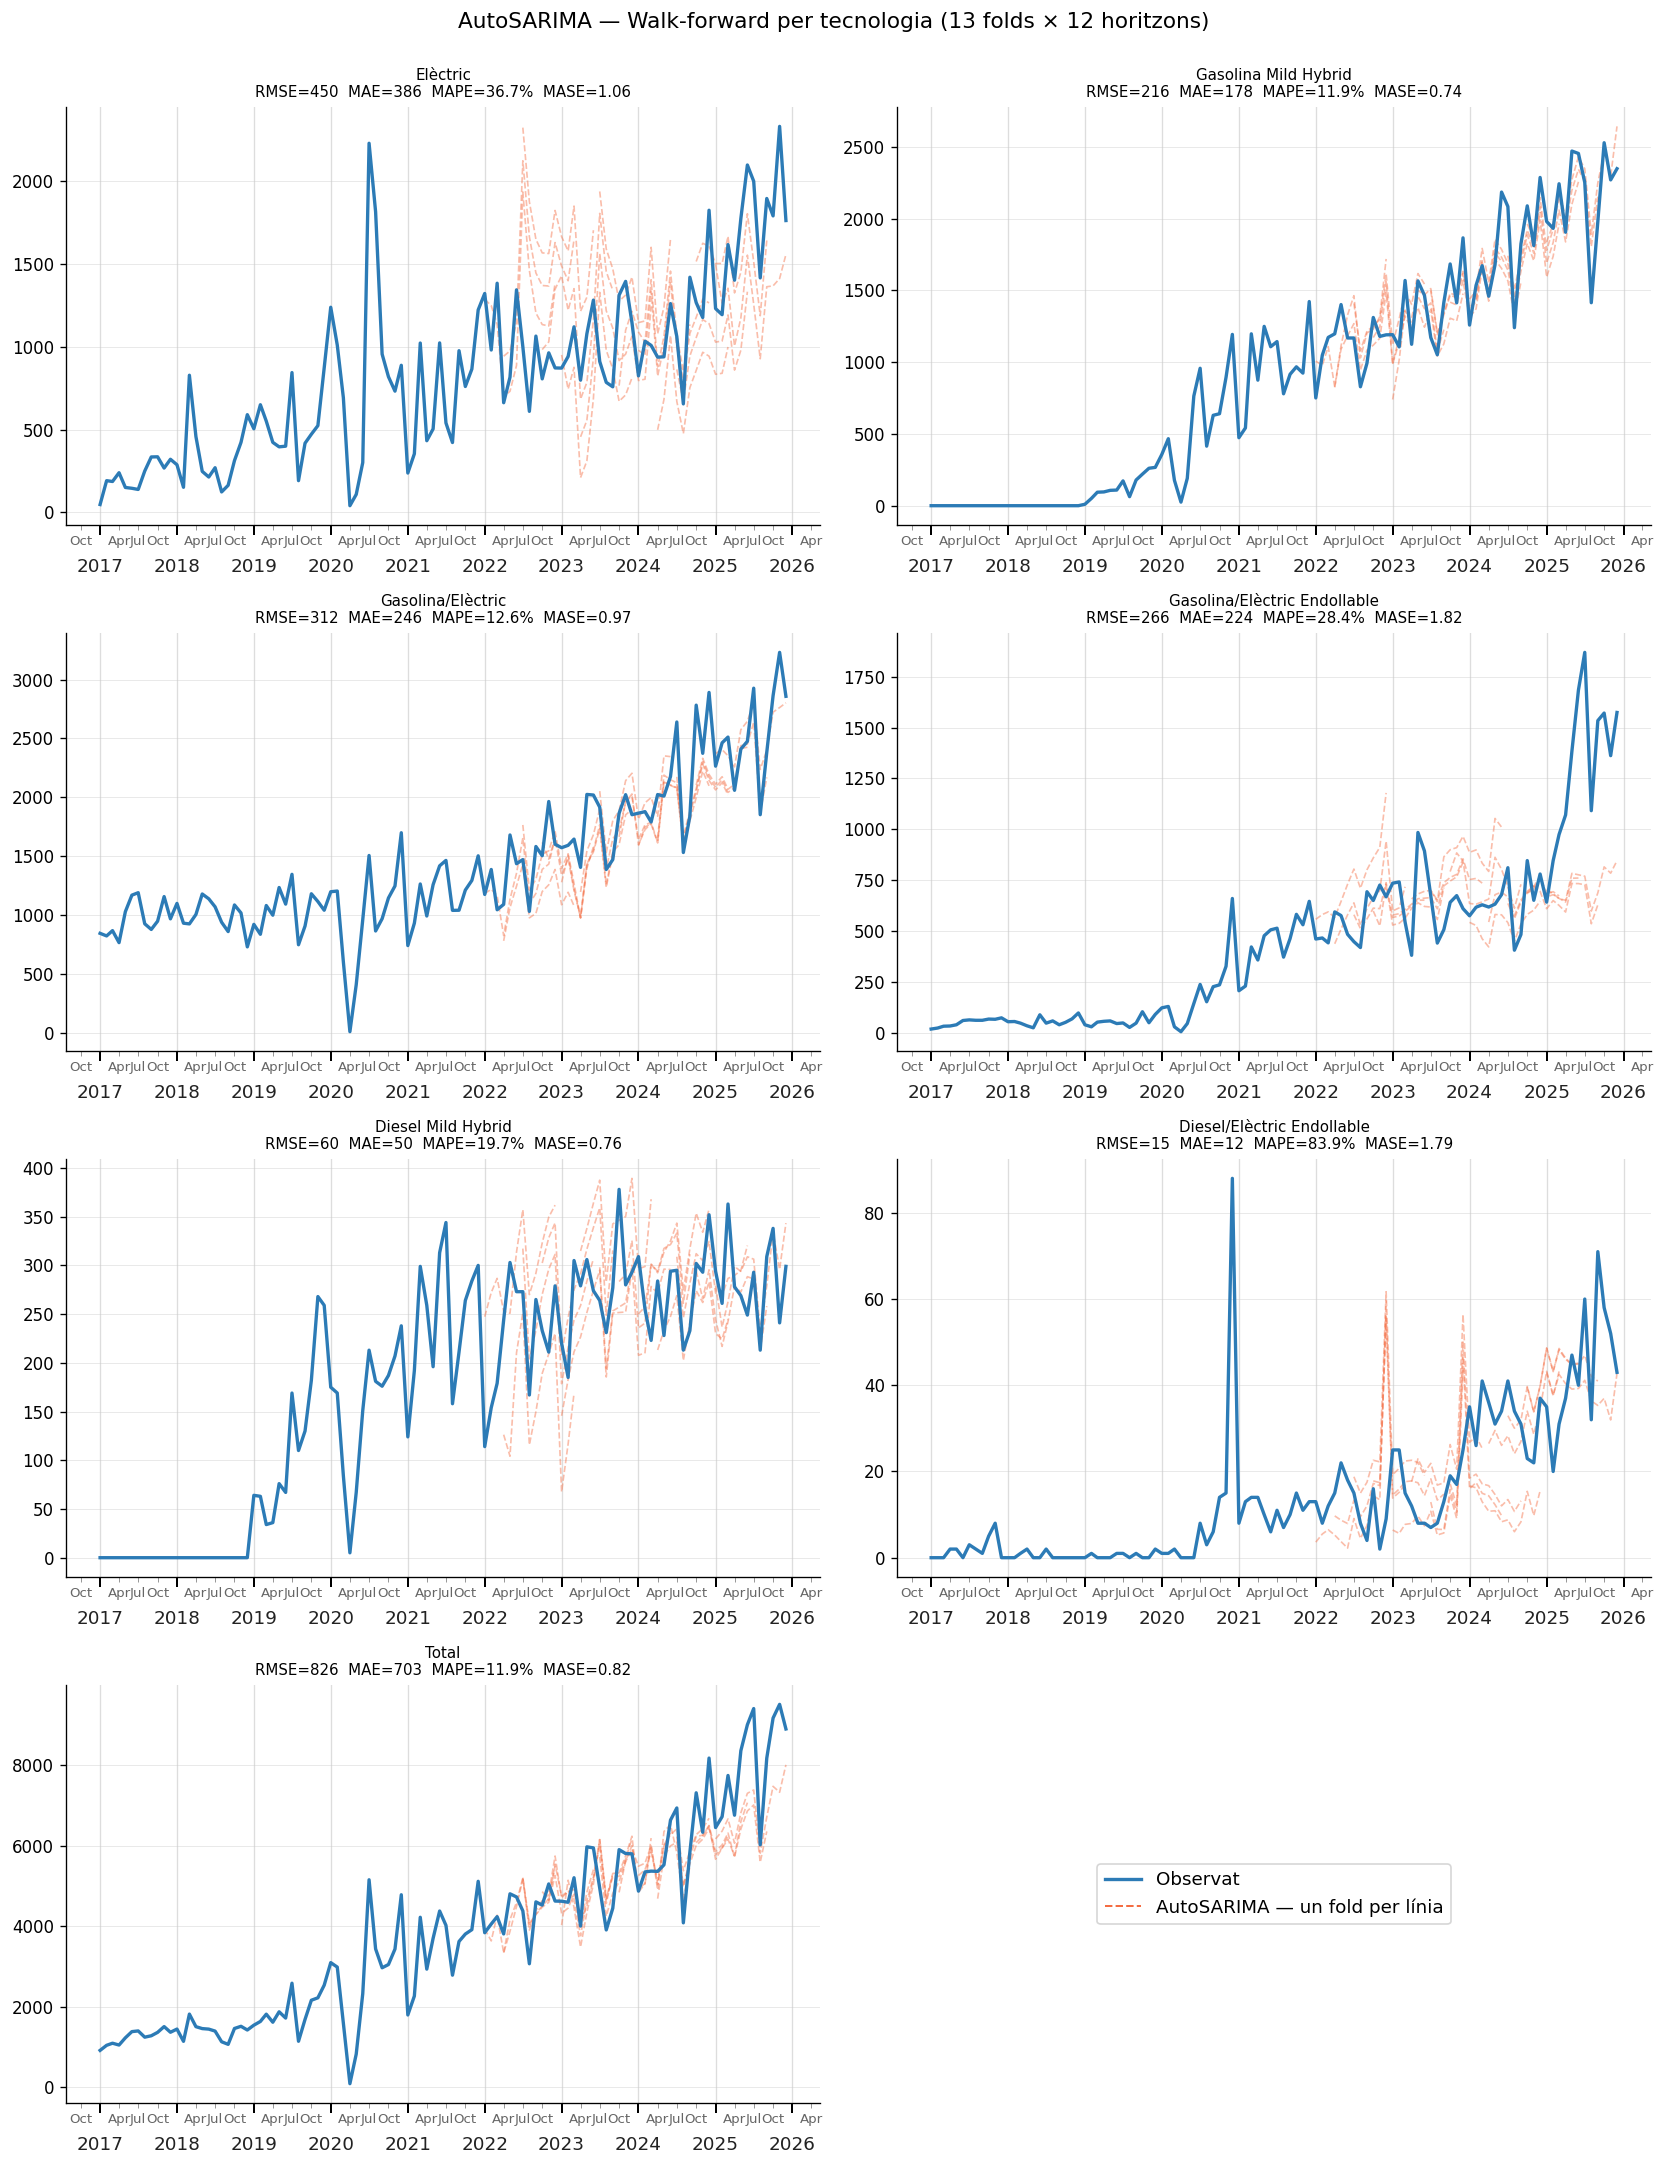

In [9]:
from plotting import plot_wfv_per_tech

plot_wfv_per_tech(
    pivot_full, df_wfv_forecasts, wfv_agg,
    tecnologies=TECNOLOGIES, model_name='AutoSARIMA',
    save_path=FIGURES_DIR / 'fig_sarima_wfv_per_tech.png',
    color_pred='#f46d43',
)
plt.show()

## 5. Guardar resultats


In [10]:
df_forecasts.to_csv(RESULTS_DIR / 'sarima_forecasts.csv', index=False)
df_metrics.to_csv(RESULTS_DIR / 'sarima_metrics.csv', index=False)
orders_df.to_csv(RESULTS_DIR / 'sarima_orders.csv', index=False)
df_wfv_metrics.to_csv(RESULTS_DIR / 'sarima_wfv_metrics.csv', index=False)
df_wfv_forecasts.to_csv(RESULTS_DIR / 'sarima_wfv_forecasts.csv', index=False)
print('Guardats:')
print('  sarima_forecasts.csv, sarima_metrics.csv, sarima_orders.csv')
print('  sarima_wfv_metrics.csv, sarima_wfv_forecasts.csv')

Guardats:
  sarima_forecasts.csv, sarima_metrics.csv, sarima_orders.csv
  sarima_wfv_metrics.csv, sarima_wfv_forecasts.csv
